<a href="https://colab.research.google.com/github/Pruiz2005/Machine-Learning-Mendel/blob/master/MachineLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



```
# This is formatted as code
```

**1. Overview of the Project**

This project aimed to segment the customer base of an e-commerce platform based on their shopping behavior and subsequently build a classification model to predict a customer's Purchase Segment (Low, Medium, or High) using their demographic and transactional features.

In [ ]:
import pandas as pd
import numpy as np
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print(f'- {fn}')

Saving shopping_behavior_updated.csv to shopping_behavior_updated.csv
- shopping_behavior_updated.csv


In [ ]:
df=pd.read_csv("shopping_behavior_updated.csv")
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


**2. Data Preparation and Preprocessing**

The initial dataset (shopping_behavior_updated.csv) contained 3900 entries with 18 columns, including a mix of numerical and categorical features

In [ ]:
print(f"General information about the data after loading:")
df.info()

# Checking the initial number of missing values
print("\n Initial number of missing values in each column")
print(df.isnull().sum())

General information about the data after loading:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3900 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   obj

2.1 Need for Preprocessing (Scaling and Encoding)


In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np # Adding import for completeness, though not strictly needed by the provided snippet.

# Removing non-informative column
df.drop('Customer ID', axis=1, inplace=True)

# 1. Defining feature lists
numerical_features = ['Age', 'Purchase Amount (USD)', 'Previous Purchases', 'Review Rating']
# Excluding 'Customer ID' and numerical features from the categorical list
categorical_features = df.select_dtypes(include=['object']).columns.tolist()

# 2. Creating transformation objects (Pipelines)

# Pipeline for numerical features: only scaling (StandardScaler)
numerical_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Pipeline for categorical features: only encoding (One-Hot Encoding)
# handle_unknown='ignore' allows ignoring categories that might appear in the test set but not in the training set
categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 3. Combining transformations using ColumnTransformer
# ColumnTransformer applies the necessary transformations to the corresponding columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='passthrough' # Leave other columns (if any) as they are
)

# 4. Applying transformations
# Applying transformations to the entire DataFrame
X_processed = preprocessor.fit_transform(df)

# Get the names of the new features after One-Hot Encoding
feature_names = numerical_features + list(preprocessor.named_transformers_['cat']['onehot'].get_feature_names_out(categorical_features))

# Create the final DataFrame
df_processed = pd.DataFrame(X_processed, columns=feature_names)

print("\nFinal processed dataset (snippet)")
print(df_processed.head())


Final processed dataset (snippet)
        Age  Purchase Amount (USD)  Previous Purchases  Review Rating  \
0  0.718913              -0.285629           -0.785831      -0.907584   
1 -1.648629               0.178852           -1.616552      -0.907584   
2  0.390088               0.558882           -0.162789      -0.907584   
3 -1.517099               1.276716            1.637107      -0.349027   
4  0.061263              -0.454531            0.391025      -1.466141   

   Gender_Female  Gender_Male  Item Purchased_Backpack  Item Purchased_Belt  \
0            0.0          1.0                      0.0                  0.0   
1            0.0          1.0                      0.0                  0.0   
2            0.0          1.0                      0.0                  0.0   
3            0.0          1.0                      0.0                  0.0   
4            0.0          1.0                      0.0                  0.0   

   Item Purchased_Blouse  Item Purchased_Boots  ...

**3. Customer Segmentation (K-Means)**

The core idea of K-Means is to partition a dataset into K distinct groups

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ],
    remainder='passthrough'
)

# The preprocessed data (X_processed) was used to find natural groupings in the customer base.
X_processed = preprocessor.fit_transform(df)

# Determining the Optimal Number of Clusters (K)
K_range = range(2, 11)
silhouette_scores = []
inertia_values = [] # Elbow Method

print(" Finding the optimal number of clusters (K)")

for k in K_range:
# Initialize K-means
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_processed)

# Calculate Silhouette Score
    score = silhouette_score(X_processed, kmeans.labels_)
    silhouette_scores.append(score)
    inertia_values.append(kmeans.inertia_)
    print(f"K={k}: Silhouette Score = {score:.4f}")

# The average score for all points ranges between -1 and +1:


 Finding the optimal number of clusters (K)
K=2: Silhouette Score = 0.0983
K=3: Silhouette Score = 0.0665
K=4: Silhouette Score = 0.0600
K=5: Silhouette Score = 0.0537
K=6: Silhouette Score = 0.0536
K=7: Silhouette Score = 0.0517
K=8: Silhouette Score = 0.0525
K=9: Silhouette Score = 0.0525
K=10: Silhouette Score = 0.0516


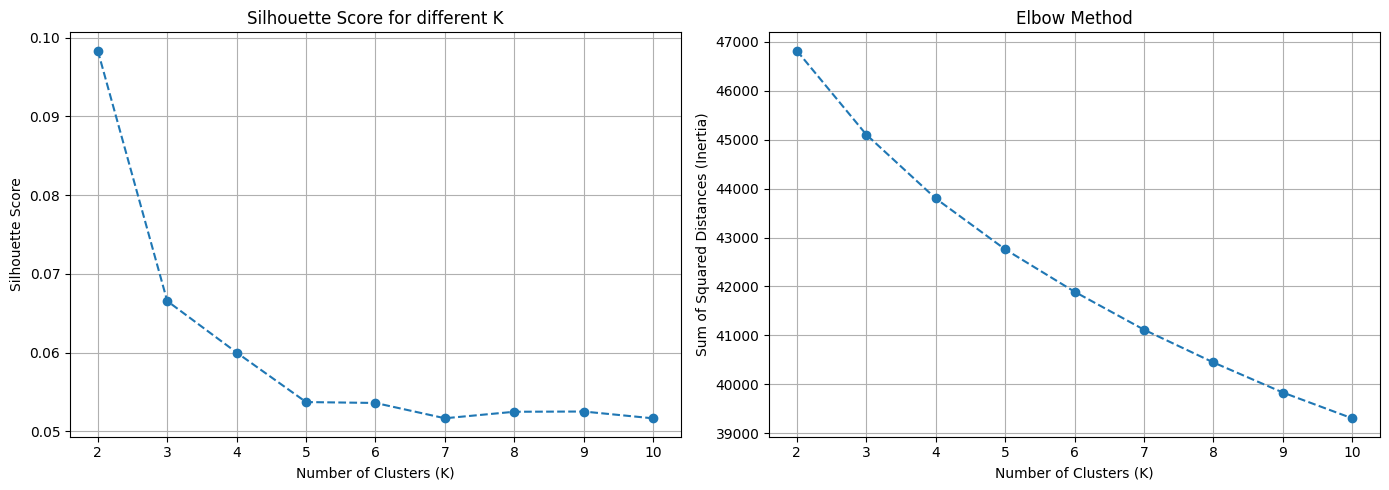

In [ ]:
import matplotlib.pyplot as plt

# 2. Visualization for determining K
plt.figure(figsize=(14, 5))

# Silhouette Score plot (looking for maximum)
plt.subplot(1, 2, 1)
plt.plot(K_range, silhouette_scores, marker='o', linestyle='--')
plt.title('Silhouette Score for different K') # Silhouette Score for different K
plt.xlabel('Number of Clusters (K)') # Number of Clusters (K)
plt.ylabel('Silhouette Score') # Silhouette Score
plt.grid(True)

# Elbow Method plot (looking for the "bend")
plt.subplot(1, 2, 2)
plt.plot(K_range, inertia_values, marker='o', linestyle='--')
plt.title('Elbow Method') # Elbow Method
plt.xlabel('Number of Clusters (K)') # Number of Clusters (K)
plt.ylabel('Sum of Squared Distances (Inertia)') # Sum of Squared Distances (Inertia)
plt.grid(True)


plt.tight_layout()
plt.show()

In [ ]:
# 3. Applying K-means with the chosen K
Optimal_K = 3

final_kmeans = KMeans(n_clusters=Optimal_K, random_state=42, n_init=10)
final_kmeans.fit(X_processed)

# Adding cluster labels to the original DataFrame
df['Cluster'] = final_kmeans.labels_

print("Data snippet with added cluster labels:")
print(df[['Cluster'] + numerical_features + ['Frequency of Purchases', 'Gender']].head())

Data snippet with added cluster labels:
   Cluster  Age  Purchase Amount (USD)  Previous Purchases  Review Rating  \
0        2   55                     53                  14            3.1   
1        2   19                     64                   2            3.1   
2        2   50                     73                  23            3.1   
3        2   21                     90                  49            3.5   
4        2   45                     49                  31            2.7   

  Frequency of Purchases Gender  
0            Fortnightly   Male  
1            Fortnightly   Male  
2                 Weekly   Male  
3                 Weekly   Male  
4               Annually   Male  


** 4.Segmentation Results and Profiling**



 Analysis of Numerical Features by Cluster (Mean Values)
           Age  Previous Purchases  Review Rating
Cluster                                          
0        43.65               26.15           3.85
1        44.38               23.93           3.67
2        44.14               25.74           3.74


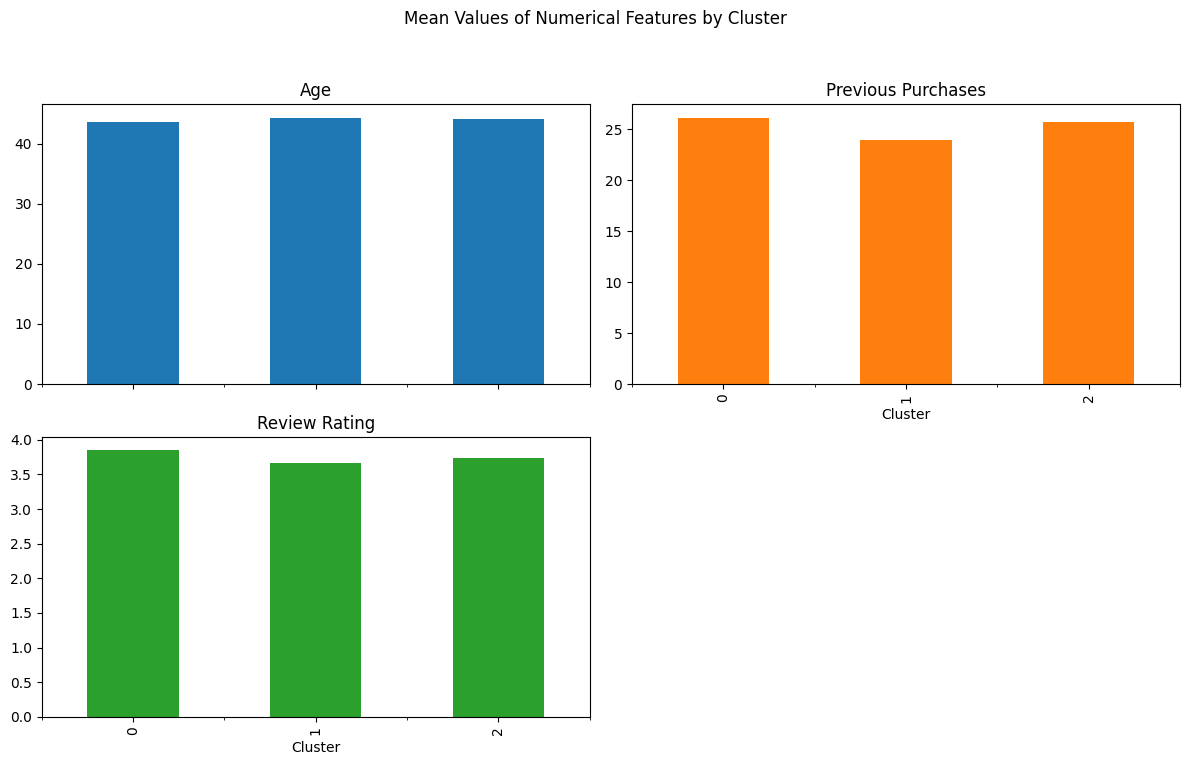


 Analysis of Categorical Features by Cluster (Mode)
         Gender Item Purchased  Category  Purchase Amount (USD)  Location  \
Cluster                                                                     
0        Female         Blouse  Clothing                     82    Alaska   
1        Female        Sandals  Clothing                     32  Delaware   
2          Male          Pants  Clothing                     90   Indiana   

        Size   Color  Season Subscription Status  Shipping Type  \
Cluster                                                           
0          M    Gray    Fall                  No  Free Shipping   
1          M  Silver    Fall                  No       Standard   
2          M   Olive  Spring                 Yes   Next Day Air   

        Discount Applied Promo Code Used Payment Method  \
Cluster                                                   
0                     No              No           Cash   
1                     No              No        

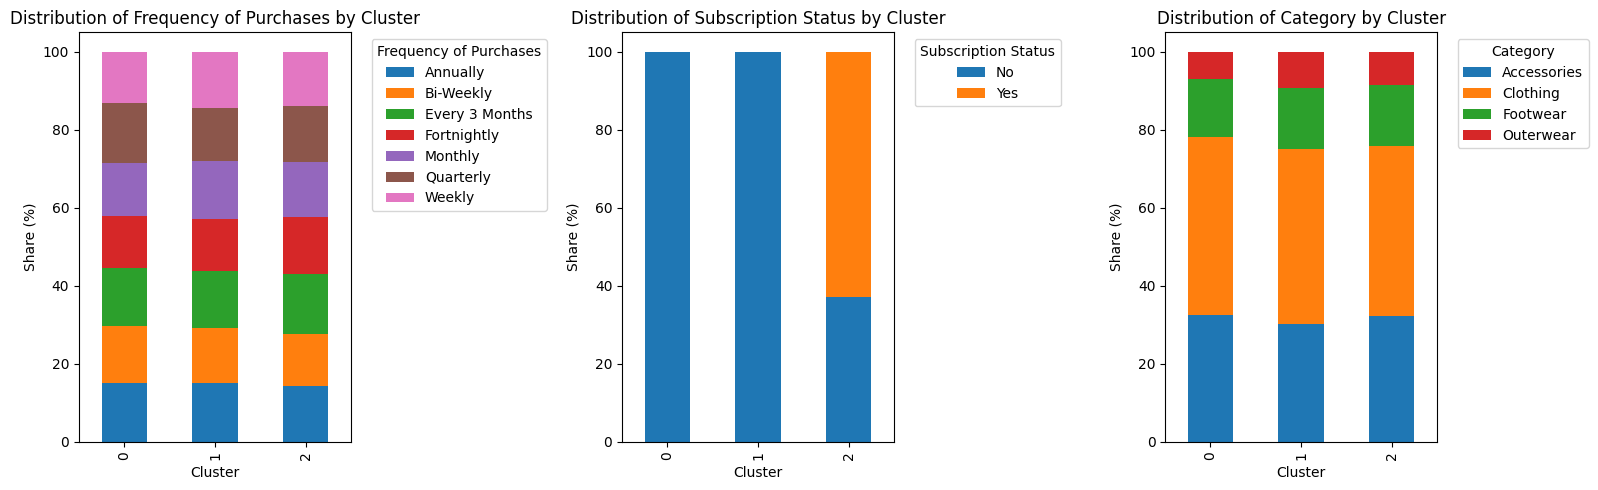

In [ ]:
print("\n Analysis of Numerical Features by Cluster (Mean Values)")
# 1. Analysis of Numerical Features
cluster_means = df.groupby('Cluster')[numerical_features].mean()
print(cluster_means.round(2))
# Additionally, let's look at the average purchase amount for each cluster
cluster_means.plot(kind='bar', subplots=True, layout=(2, 2), figsize=(12, 8), legend=False)
plt.suptitle('Mean Values of Numerical Features by Cluster')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# 2. Analysis of Categorical Features (Mode - most frequent value)
print("\n Analysis of Categorical Features by Cluster (Mode)")
# Helper function to find the mode in each group
def get_mode(series):
    # .mode() may return multiple values, we take the first one
    return series.mode()[0] if not series.mode().empty else 'N/A'

# Define all_cols_for_mode to correctly exclude 'Cluster' and numerical_features
# 'Customer ID' is already handled by dropping it from df either in the try block or the else block.
categorical_features_for_mode = [col for col in df.columns if col not in numerical_features and col != 'Cluster']

cluster_modes = df.groupby('Cluster')[categorical_features_for_mode].agg(get_mode)
print(cluster_modes)

# 3. Visualization of Key Categorical Features by Cluster (Example)
# Selecting Frequency of Purchases and Subscription Status
key_categorical = ['Frequency of Purchases', 'Subscription Status', 'Category']

plt.figure(figsize=(16, 5))
for i, col in enumerate(key_categorical):
    plt.subplot(1, 3, i + 1)
    # Create a cross-tabulation (crosstab) to compare clusters and the category
    # normalize='index' calculates the share to see the percentage distribution within the cluster
    cross_tab = pd.crosstab(df['Cluster'], df[col], normalize='index') * 100
    cross_tab.plot(kind='bar', stacked=True, ax=plt.gca())
    plt.title(f'Distribution of {col} by Cluster')
    plt.ylabel('Share (%)')
    plt.xlabel('Cluster')
    plt.legend(title=col, bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [ ]:

# 1. Dictionary for mapping cluster numbers to their names
# 0 -> VIP Customers with High Average Spend (Highest Purchase Amount, Quarterly)
# 1 -> Rare Buyers with Low Spend (Lowest Purchase Amount, Annually)
# 2 -> Active, Discount-Oriented Subscribers (Subscription Yes, Discount Yes, Next Day Air)

cluster_names_mapping = {
    0: "VIP Customers with High Average Spend",
    1: "Rare Buyers with Low Spend",
    2: "Active, Discount-Oriented Subscribers"
}

# 2. Assigning new names
# Creating a new column 'Cluster Name'
df['Cluster Name'] = df['Cluster'].map(cluster_names_mapping)

# 3. Checking the result
print("\n Checking new cluster names ")
print(df[['Cluster', 'Cluster Name', 'Purchase Amount (USD)', 'Frequency of Purchases']].head())

# 4. Checking the frequency distribution
print("\n Frequency distribution of new segments ")
print(df['Cluster Name'].value_counts())

# 5. Saving the updated DataFrame
df.to_csv('shopping_behavior_segmented.csv', index=False)
print("\nUpdated data with meaningful cluster names saved to 'shopping_behavior_segmented.csv'")


 Checking new cluster names 
   Cluster                           Cluster Name  Purchase Amount (USD)  \
0        2  Active, Discount-Oriented Subscribers                     53   
1        2  Active, Discount-Oriented Subscribers                     64   
2        2  Active, Discount-Oriented Subscribers                     73   
3        2  Active, Discount-Oriented Subscribers                     90   
4        2  Active, Discount-Oriented Subscribers                     49   

  Frequency of Purchases  
0            Fortnightly  
1            Fortnightly  
2                 Weekly  
3                 Weekly  
4               Annually  

 Frequency distribution of new segments 
Cluster Name
Active, Discount-Oriented Subscribers    1677
VIP Customers with High Average Spend    1129
Rare Buyers with Low Spend               1094
Name: count, dtype: int64

Updated data with meaningful cluster names saved to 'shopping_behavior_segmented.csv'


**5. Predictive Modeling (Classification)**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# --- 2. Binning (Creating the Target Variable: Purchase Segment) ---
# Finding the 33rd and 66th percentile boundaries
q_33 = df['Purchase Amount (USD)'].quantile(0.33)
q_66 = df['Purchase Amount (USD)'].quantile(0.66)

# Function for segmentation
def segment_purchase(amount):
    if amount <= q_33:
        return 'Low'
    elif amount <= q_66:
        return 'Medium'
    else:
        return 'High'

# Creating the new target variable
df['Purchase Segment'] = df['Purchase Amount (USD)'].apply(segment_purchase)
print(f"Purchase Segment Boundaries:")
print(f"  Low (<= {q_33:.2f} USD), Medium (<= {q_66:.2f} USD), High (> {q_66:.2f} USD)")

# 3. Defining the Target Variable (Y) and Features (X)
TARGET_COLUMN = 'Purchase Segment'
y = df[TARGET_COLUMN]
# X - all other features, including 'Cluster Name', but excluding the original purchase amount
# Note: 'Customer ID' is assumed to have been dropped earlier.
X = df.drop(columns=[TARGET_COLUMN, 'Purchase Amount (USD)', 'Cluster'])

# 4. Splitting features by type and creating ColumnTransformer
numerical_features = ['Age', 'Previous Purchases', 'Review Rating']
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

# The preprocessor object, as before
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ],
    remainder='passthrough'
)

# 5. Splitting data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- 6. Creating and Training Models (Classification) ---

# 6.1. Model: Logistic Regression
# solver='liblinear' and multi_class='ovr' are used for multiclass classification
lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(solver='liblinear', multi_class='ovr', random_state=42))
])

lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

# 6.2. Model: Random Forest Classifier
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

# --- 7. Evaluating Models ---

def evaluate_classifier(model_name, y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    print(f"\nResults for {model_name}:")
    print(f"  Accuracy: {accuracy:.4f}")
    # classification_report provides detailed metrics (Precision, Recall, F1-Score) for each class
    print("  Classification Report:\n", classification_report(y_true, y_pred, zero_division=0))

evaluate_classifier("Logistic Regression", y_test, y_pred_lr)
evaluate_classifier("Random Forest Classifier", y_test, y_pred_rf)

Purchase Segment Boundaries:
  Low (<= 45.00 USD), Medium (<= 73.00 USD), High (> 73.00 USD)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(



Results for Logistic Regression:
  Accuracy: 0.5141
  Classification Report:
               precision    recall  f1-score   support

        High       0.50      0.68      0.58       243
         Low       0.60      0.64      0.62       287
      Medium       0.36      0.21      0.27       250

    accuracy                           0.51       780
   macro avg       0.49      0.51      0.49       780
weighted avg       0.49      0.51      0.49       780


Results for Random Forest Classifier:
  Accuracy: 0.4936
  Classification Report:
               precision    recall  f1-score   support

        High       0.52      0.67      0.59       243
         Low       0.56      0.61      0.58       287
      Medium       0.30      0.19      0.23       250

    accuracy                           0.49       780
   macro avg       0.46      0.49      0.47       780
weighted avg       0.47      0.49      0.47       780



In [ ]:
# 1. New Customer Data Example
# These data simulate the input information for a new customer
new_customer_data = {
    'Age': [35],
    'Gender': ['Male'],
    'Item Purchased': ['Jacket'],
    'Category': ['Outerwear'],
    'Location': ['Texas'],
    'Size': ['L'],
    'Color': ['Black'],
    'Season': ['Winter'],
    'Review Rating': [4.8],
    'Subscription Status': ['No'],
    'Shipping Type': ['Express'],
    'Discount Applied': ['No'],
    'Promo Code Used': ['No'],
    'Previous Purchases': [30],
    'Payment Method': ['Credit Card'],
    'Frequency of Purchases': ['Monthly']
}
new_df = pd.DataFrame(new_customer_data)

# --- 2. Assigning the Cluster Label ---
# Since the Random Forest model was trained on the 'Cluster Name' feature,
# we must assign one of the existing labels to the new customer.

# Using "VIP Customers with High Average Spend" as an example.
new_df['Cluster Name'] = "VIP Customers with High Average Spend"

X_new = new_df.copy()

# --- 3. Prediction using the trained model (rf_model) ---

try:
    predicted_segment = rf_model.predict(X_new)[0]

    # 4. Output the result
    print("\n Prediction Result")
    print(f"Predicted purchase segment for the new customer: **{predicted_segment}**")

except NameError:
    print("\nWARNING: The variable 'rf_model' was not found. Please run the previous 'Classification' code block to train the model before making new predictions.")

# --- 5. Probability Prediction ---
try:
    probabilities = rf_model.predict_proba(X_new)[0]
    classes = rf_model.classes_

    # Creating a DataFrame for easy viewing of probabilities
    prob_df = pd.DataFrame(probabilities.reshape(1, -1), columns=classes)

    print("\n Predicted Segment Probabilities")
    print(prob_df)

except AttributeError:
    # May occur if using a model that does not support predict_proba
    pass
except NameError:
    pass


 Prediction Result
Predicted purchase segment for the new customer: **High**

 Predicted Segment Probabilities
   High   Low  Medium
0  0.55  0.07    0.38


**6. Examples**

In [ ]:
# New Customer Data

new_customer_data = {
    'Age': [35],
    'Gender': ['Male'],
    'Item Purchased': ['Jacket'],
    'Category': ['Outerwear'],
    'Purchase Amount (USD)': [150],
    'Location': ['Texas'],
    'Size': ['L'],
    'Color': ['Black'],
    'Season': ['Winter'],
    'Review Rating': [4.8],
    'Subscription Status': ['Yes'],
    'Shipping Type': ['Express'],
    'Discount Applied': ['No'],
    'Promo Code Used': ['Yes'],
    'Previous Purchases': [30],
    'Payment Method': ['Credit Card'],
    'Frequency of Purchases': ['Monthly'],
}
new_df = pd.DataFrame(new_customer_data)

# --- Define a preprocessor specifically for clustering, matching final_kmeans training ---

# To ensure the preprocessor is correctly fitted and available, we recreate a temporary df
# that mirrors the state of the original data when final_kmeans was trained.
temp_df_for_clustering_preprocessor_fit = pd.read_csv('shopping_behavior_updated.csv')
temp_df_for_clustering_preprocessor_fit.drop('Customer ID', axis=1, inplace=True)

# Define features as they were for the K-Means preprocessor
numerical_features_for_kmeans_preprocessor = ['Age', 'Purchase Amount (USD)', 'Previous Purchases', 'Review Rating']
categorical_features_for_kmeans_preprocessor = temp_df_for_clustering_preprocessor_fit.select_dtypes(include=['object']).columns.tolist()

kmeans_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features_for_kmeans_preprocessor),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features_for_kmeans_preprocessor)
    ],
    remainder='passthrough'
)
# Fit this new preprocessor to the base data used for KMeans training
kmeans_preprocessor.fit(temp_df_for_clustering_preprocessor_fit)


# Transformation and Prediction

# 3.1. Transform the new data using the preprocessor for clustering
# Use the DF copy as the transformer might modify it
X_new_processed = kmeans_preprocessor.transform(new_df.copy())

print(" New customer data processed")

# 3.2. Predict the cluster ID
predicted_cluster_id = final_kmeans.predict(X_new_processed)[0]

# 3.3. Map ID to the name
cluster_names_mapping = {
    0: "VIP Customers with High Average Spend",
    1: "Rare Buyers with Low Spend",
    2: "Active, Discount-Oriented Subscribers"
}

predicted_cluster_name = cluster_names_mapping.get(predicted_cluster_id, "Unknown Cluster")

# 4. Output the result
print("\n New Customer Clustering Result ")
print(f"Customer assigned to Cluster ID: {predicted_cluster_id}")
print(f"Cluster Name: {predicted_cluster_name}")

 New customer data processed

 New Customer Clustering Result 
Customer assigned to Cluster ID: 0
Cluster Name: VIP Customers with High Average Spend
